In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import NearestNeighbors # 新增：用于构建空间边

# ==========================================
# 0. 导入库 (同前)
# ==========================================
try:
    from torch_geometric.data import Data
    from torch_geometric.nn import SAGEConv # 使用 SAGEConv 替代 GCNConv，效果通常更好
except ImportError:
    print("错误: 请先安装 PyTorch Geometric: pip install torch_geometric")
    exit()

# ==========================================
# 1. 辅助函数：计算高度角和方位角 (复用之前的几何函数)
# ==========================================
def xyz2llh(xyz):
    x, y, z = xyz[:, 0], xyz[:, 1], xyz[:, 2]
    a, e2 = 6378137.0, 0.00669437999014
    p = np.sqrt(x**2 + y**2)
    theta = np.arctan2(z * a, p * np.sqrt(a**2 - z**2 * e2))
    lon, lat = np.arctan2(y, x), np.arctan2(z + (e2 * a * (np.sin(theta)**3)), p - (e2 * a * (np.cos(theta)**3)))
    return np.column_stack((lat, lon))

def ecef2enu(rec_xyz, sat_xyz):
    rec_llh = xyz2llh(rec_xyz)
    lat, lon = rec_llh[:, 0], rec_llh[:, 1]
    rx, ry, rz = sat_xyz[:, 0] - rec_xyz[:, 0], sat_xyz[:, 1] - rec_xyz[:, 1], sat_xyz[:, 2] - rec_xyz[:, 2]
    e = -np.sin(lon) * rx + np.cos(lon) * ry
    n = -np.sin(lat) * np.cos(lon) * rx - np.sin(lat) * np.sin(lon) * ry + np.cos(lat) * rz
    u = np.cos(lat) * np.cos(lon) * rx + np.cos(lat) * np.sin(lon) * ry + np.sin(lat) * rz
    elev = np.arctan2(u, np.sqrt(e**2 + n**2))
    azim = np.arctan2(e, n)
    return elev, azim

def blh2enu(rec_blh, sat_blh):
    lat, lon = rec_blh[:, 0], rec_blh[:, 1]
    rx = (sat_blh[:, 2] * np.cos(sat_blh[:, 0]) * np.cos(sat_blh[:, 1])) - (rec_blh[:, 2] * np.cos(rec_blh[:, 0]) * np.cos(rec_blh[:, 1]))
    ry = (sat_blh[:, 2] * np.cos(sat_blh[:, 0]) * np.sin(sat_blh[:, 1])) - (rec_blh[:, 2] * np.cos(rec_blh[:, 0]) * np.sin(rec_blh[:, 1]))
    rz = (sat_blh[:, 2] * np.sin(sat_blh[:, 0])) - (rec_blh[:, 2] * np.sin(rec_blh[:, 0]))
    e = -np.sin(lon) * rx + np.cos(lon) * ry
    n = -np.sin(lat) * np.cos(lon) * rx - np.sin(lat) * np.sin(lon) * ry + np.cos(lat) * rz
    u = np.cos(lat) * np.cos(lon) * rx + np.cos(lat) * np.sin(lon) * ry + np.sin(lat) * rz
    elev = np.arctan2(u, np.sqrt(e**2 + n**2))
    azim = np.arctan2(e, n)
    return elev, azim

# ==========================================
# 2. 优化的数据构建与图构建 (核心修改)
# ==========================================

# --- 加载数据 (假设路径同上) ---
data_dir = r"Mydata/"
# sTEC_filename = os.path.join(data_dir, f"obs_sTEC_2024128_1000_regional.npz")
sTEC_filename = os.path.join(data_dir, f"obs_sTEC_2024128_1000_regional_big.npz")
try:
    sTEC_data = np.load(sTEC_filename, allow_pickle=True)
    slantTEC = sTEC_data['slantTEC']
    Rec_XYZ = sTEC_data['Rec_XYZ']
    Sat_XYZ = sTEC_data['Sat_XYZ']
    Rec_BLH = sTEC_data['Rec_BLH']
    Sat_BLH = sTEC_data['Sat_BLH']
    # 形状修正
    if Rec_XYZ.shape[0] == 3: Rec_XYZ = Rec_XYZ.T
    if Sat_XYZ.shape[0] == 3: Sat_XYZ = Sat_XYZ.T
    if Rec_BLH.shape[0] == 3: Rec_BLH = Rec_BLH.T
    if Sat_BLH.shape[0] == 3: Sat_BLH = Sat_BLH.T
except:
    print("未找到文件，生成模拟数据演示...")
    Rec_XYZ = np.random.randn(20, 3) * 100 + 6371000
    Sat_XYZ = np.random.randn(10, 3) * 1000 + 20000000
    slantTEC = np.random.rand(200) * 50 + 20
    Rec_XYZ = Rec_XYZ[np.random.randint(0, 20, 200)]
    Sat_XYZ = Sat_XYZ[np.random.randint(0, 10, 200)]
    Rec_BLH = np.random.rand(200, 3)
    Sat_BLH = np.random.rand(200, 3)

In [3]:
# --- 1. 获取唯一结点 ---
unique_rec, rec_indices = np.unique(Rec_XYZ, axis=0, return_inverse=True)
unique_sat, sat_indices = np.unique(Sat_XYZ, axis=0, return_inverse=True)
# unique_rec, rec_indices = np.unique(Rec_BLH, axis=0, return_inverse=True)
# unique_sat, sat_indices = np.unique(Sat_BLH, axis=0, return_inverse=True)
n_rec = len(unique_rec)
n_sat = len(unique_sat)
sat_indices_shifted = sat_indices + n_rec

# --- 2. 构建射线边 + 边特征 (高度角/方位角) ---
# 计算所有样本的高度角和方位角作为边特征
print("正在计算边特征 (高度角/方位角)...")
elev, azim = ecef2enu(Rec_XYZ, Sat_XYZ)
# elev, azim = blh2enu(Rec_BLH, Sat_BLH)
ray_edge_attr = np.stack([elev, azim], axis=1) # Shape: (N_rays, 2)

# 构建射线边索引 (双向)
ray_edge_index = np.stack([rec_indices, sat_indices_shifted], axis=0)
ray_edge_index = np.concatenate([ray_edge_index, ray_edge_index[::-1]], axis=1)
# 边特征也复制一份给反向边
ray_edge_attr = np.concatenate([ray_edge_attr, ray_edge_attr], axis=0)

# 标签
y = np.concatenate([slantTEC, slantTEC], axis=0)
ray_mask_len = len(y) # 记录射线边的数量，后续用于掩码

# --- 3. 构建接收机之间的空间边 (KNN) ---
# 关键优化：让相邻的接收机相连，使模型能利用空间相关性
print("正在构建接收机空间邻接图 (KNN)...")
k = 4 # 每个接收机连接最近的 4 个接收机
nbrs = NearestNeighbors(n_neighbors=k+1).fit(unique_rec) # k+1 因为包含自己
distances, indices = nbrs.kneighbors(unique_rec)

# 构建接收机-接收机边索引 (排除自环)
rec_rec_src = []
rec_rec_dst = []
for i in range(n_rec):
    for j_idx, neighbor_idx in enumerate(indices[i]):
        if i != neighbor_idx: # 排除自己
            rec_rec_src.append(i)
            rec_rec_dst.append(neighbor_idx)

# 添加到总边列表
spatial_edge_index = np.stack([rec_rec_src, rec_rec_dst], axis=0)
# 空间边没有物理含义的边特征，填充 0 (模型将主要依赖节点信息)
spatial_edge_attr = np.zeros((spatial_edge_index.shape[1], 2)) 
# [FIX] 为空间边创建虚拟标签（填充0），使 y 的长度与总边数一致
spatial_y = np.zeros(spatial_edge_index.shape[1])
y = np.concatenate([y, spatial_y], axis=0)

# --- 4. 合并所有边 ---
# 最终图包含：射线边(观测) + 接收机空间边(辅助)
final_edge_index = np.concatenate([ray_edge_index, spatial_edge_index], axis=1)
final_edge_attr = np.concatenate([ray_edge_attr, spatial_edge_attr], axis=0)

# --- 5. 准备 Tensor ---
x = np.concatenate([unique_rec, unique_sat], axis=0)
scaler_node = StandardScaler()
x = scaler_node.fit_transform(x)
x = torch.FloatTensor(x)

scaler_edge = StandardScaler()
# 只用射线边的特征来fit标准化，防止空间边的0影响分布
scaler_edge.fit(ray_edge_attr) 
edge_attr = scaler_edge.transform(final_edge_attr)
edge_attr = torch.FloatTensor(edge_attr)

edge_index = torch.LongTensor(final_edge_index)

# # 1. 先进行 Log1p 变换，压缩大值，拉伸小值区间
# y_log = np.log1p(y) 
# # 2. 再进行标准化 (Log空间下的标准化分布通常这更好)
# scaler_y = StandardScaler()
# y_scaled = scaler_y.fit_transform(y_log.reshape(-1, 1)).flatten()
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
y = torch.FloatTensor(y_scaled).unsqueeze(1)

data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

# --- 6. 划分掩码 (只在射线边上划分训练集/测试集) ---
num_rays = ray_mask_len
indices = np.arange(num_rays)
np.random.shuffle(indices)
train_size = int(0.8 * num_rays)

train_ray_indices = indices[:train_size]
test_ray_indices = indices[train_size:]

# 创建全图的掩码，默认 False
train_mask = torch.zeros(data.edge_index.shape[1], dtype=torch.bool)
test_mask = torch.zeros(data.edge_index.shape[1], dtype=torch.bool)

# 只在射线边部分赋值 True
train_mask[train_ray_indices] = True
test_mask[test_ray_indices] = True

data.train_mask = train_mask
data.test_mask = test_mask

print(f"图构建完成: 结点={data.x.shape[0]}, 总边数={data.edge_index.shape[1]}, 射线边={num_rays}")
print(f"边特征维度: {data.edge_attr.shape} (高度角, 方位角)")

# ==========================================
# 3. 定义优化的 GNN 模型
# ==========================================

class ImprovedSTEC_GNN(nn.Module):
    def __init__(self, num_node_features, num_edge_features):
        super(ImprovedSTEC_GNN, self).__init__()
        
        # 1. 结点嵌入
        self.lin_node = nn.Linear(num_node_features, 64) #32
        
        # 2. GNN 层 (使用 SAGEConv，它比 GCN 更适合处理这种包含异质边的图)
        self.conv1 = SAGEConv(64, 64) # 32, 32
        self.conv2 = SAGEConv(64, 32) # 32, 16
        
        # 3. 边解码器 (关键改进：结合边特征)
        # 输入: [源节点向量, 目标节点向量, 边特征(高度角/方位角)]
        decoder_input_dim = 32 * 2 + num_edge_features
        
        self.edge_decoder = nn.Sequential(
            nn.Linear(decoder_input_dim, 64), #32
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32), # 32, 16
            nn.ReLU(),
            nn.Linear(32, 1) # 16, 1
        )

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr
        
        # A. 结点特征更新
        x = self.lin_node(x)
        x = F.relu(x)
        
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=0.2, training=self.training)
        
        x = self.conv2(x, edge_index)
        
        # B. 边特征提取与预测
        src = x[edge_index[0]]  # 所有边的源节点
        dst = x[edge_index[1]]  # 所有边的目标节点
        
        # 拼接: Node_Embedding + Node_Embedding + Edge_Features
        # 这样模型既知道位置关系(Embedding)，也知道几何角度
        edge_input = torch.cat([src, dst, edge_attr], dim=1)
        
        out = self.edge_decoder(edge_input)
        return out
# 实例化新模型
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ImprovedSTEC_GNN(num_node_features=3, num_edge_features=2).to(device)
# 统计训练样本数量
n_train_samples = int(data.train_mask.sum())
n_test_samples = int(data.test_mask.sum())
n_total_edges = data.edge_index.shape[1]
# 如果你想顺便算一下比例
total_params = sum(p.numel() for p in model.parameters())
ratio = total_params / n_train_samples if n_train_samples > 0 else 0

print(f"\n模型参数量: {total_params}")
print(f"当前参数/样本比率: {ratio:.2f} (理想值 < 1.0)")
# 预期输出应该在 1300 左右 (之前约为 4900)

# ==========================================
# 4. 训练与评估
# ==========================================
class RobustEarlyStopping:
    """
    带滑动平均的早停机制，专门解决 Loss 震荡导致早停过早的问题。
    """
    def __init__(self, patience=30, min_delta=1e-5, window_size=5):
        self.patience = patience
        self.min_delta = min_delta
        self.window_size = window_size # 计算平均值的窗口大小
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.loss_history = [] # 记录最近的 loss
        self.best_epoch = 0 # [FIX] 初始化 best_epoch

    def __call__(self, val_loss, epoch): # [FIX] 增加 epoch 参数
        self.loss_history.append(val_loss)
        
        # 保持历史记录长度不超过窗口大小
        if len(self.loss_history) > self.window_size:
            self.loss_history.pop(0)
            
        # 如果历史记录还不够，暂时不触发早停逻辑（给模型一点热身时间）
        if len(self.loss_history) < self.window_size:
            return

        # 计算当前窗口内的平均 Loss
        current_avg_loss = np.mean(self.loss_history)

        if self.best_loss is None:
            self.best_loss = current_avg_loss
            self.best_epoch = epoch # [FIX] 记录当前 epoch
        elif current_avg_loss > self.best_loss - self.min_delta:
            # 如果平均 Loss 没有显著下降，计数器 +1
            self.counter += 1
            # print(f"EarlyStopping counter: {self.counter} out of {self.patience} (Current Avg Loss: {current_avg_loss:.6f})")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            # 如果有显著下降，更新最佳 Loss，并重置计数器
            self.best_loss = current_avg_loss
            self.best_epoch = epoch # [FIX] 更新最佳 epoch
            self.counter = 0
# patience 可以稍微大一点，因为我们用了平均法，判断更准了
early_stopping = RobustEarlyStopping(patience=500, min_delta=1e-6, window_size=20)




data = data.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.MSELoss()

print("开始训练优化后的 GNN 模型...")
losses = []
val_losses = []
epochs = 15000
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    out = model(data)
    
    # 只计算射线边上的损失 (忽略空间辅助边)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    # 每个 epoch 都算一次验证集 loss
    model.eval()
    with torch.no_grad():
        val_out = model(data)
        val_loss = criterion(val_out[data.test_mask], data.y[data.test_mask]).item()
    val_losses.append(val_loss)
    model.train()
    
    if (epoch + 1) % (epochs/100) == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.6f}')

    early_stopping(val_loss, epoch)
    if early_stopping.early_stop:
        print(f"Early stopping at epoch {epoch+1}, best val loss at epoch {early_stopping.best_epoch}")
        break


正在计算边特征 (高度角/方位角)...
正在构建接收机空间邻接图 (KNN)...
图构建完成: 结点=363, 总边数=9258, 射线边=8098
边特征维度: torch.Size([9258, 2]) (高度角, 方位角)

模型参数量: 19041
当前参数/样本比率: 2.94 (理想值 < 1.0)
开始训练优化后的 GNN 模型...
Epoch [150/15000], Loss: 0.126768
Epoch [300/15000], Loss: 0.071181
Epoch [450/15000], Loss: 0.057626
Epoch [600/15000], Loss: 0.044197
Epoch [750/15000], Loss: 0.038796
Epoch [900/15000], Loss: 0.040294
Epoch [1050/15000], Loss: 0.032315
Epoch [1200/15000], Loss: 0.041716
Epoch [1350/15000], Loss: 0.030362
Epoch [1500/15000], Loss: 0.029954
Epoch [1650/15000], Loss: 0.027392
Epoch [1800/15000], Loss: 0.033087
Epoch [1950/15000], Loss: 0.030751
Epoch [2100/15000], Loss: 0.028620
Epoch [2250/15000], Loss: 0.022120
Epoch [2400/15000], Loss: 0.023113
Epoch [2550/15000], Loss: 0.021102
Epoch [2700/15000], Loss: 0.021359
Epoch [2850/15000], Loss: 0.021464
Epoch [3000/15000], Loss: 0.020392
Epoch [3150/15000], Loss: 0.022207
Epoch [3300/15000], Loss: 0.020147
Epoch [3450/15000], Loss: 0.018161
Epoch [3600/15000], Los


优化后的 GNN 评估结果:
RMSE: 6.2482 TECU
R2 Score: 0.9851


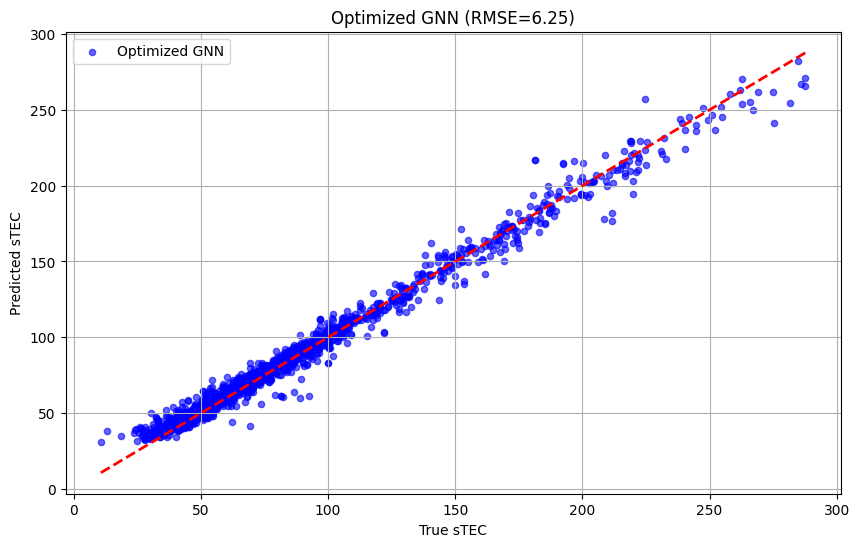

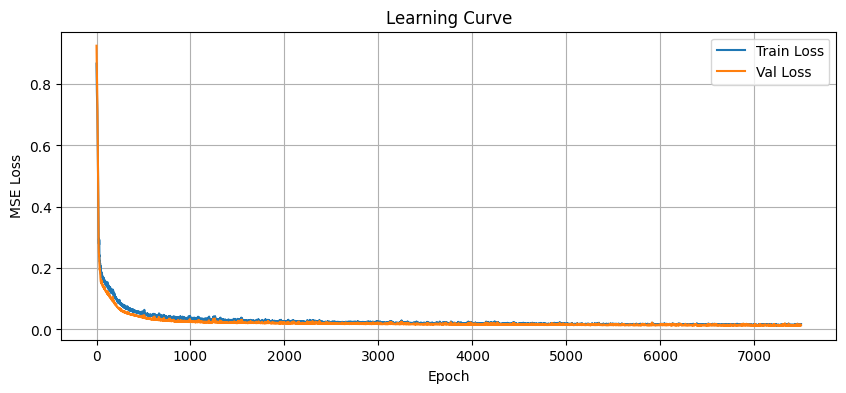

In [4]:
# --- 评估 ---
model.eval()
with torch.no_grad():
    pred = model(data)
    # 提取测试集
    pred_test = pred[data.test_mask].cpu().numpy()
    y_test = data.y[data.test_mask].cpu().numpy()
    
    # 反标准化
    pred_test_inv = scaler_y.inverse_transform(pred_test)
    y_test_inv = scaler_y.inverse_transform(y_test)
    
    # # [修改] 反 Log1p (expm1)
    # pred_test_inv = np.expm1(pred_test_inv_scaled)
    # y_test_inv = np.expm1(y_test_inv_scaled)
    
    rmse = np.sqrt(mean_squared_error(y_test_inv, pred_test_inv))
    r2 = r2_score(y_test_inv, pred_test_inv)

print(f"\n优化后的 GNN 评估结果:")
print(f"RMSE: {rmse:.4f} TECU")
print(f"R2 Score: {r2:.4f}")

plt.figure(figsize=(10, 6))
plt.scatter(y_test_inv, pred_test_inv, alpha=0.6, label='Optimized GNN', s=20, color='blue')
plt.plot([y_test_inv.min(), y_test_inv.max()], [y_test_inv.min(), y_test_inv.max()], 'r--', lw=2)
plt.xlabel('True sTEC')
plt.ylabel('Predicted sTEC')
plt.title(f'Optimized GNN (RMSE={rmse:.2f})')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

In [5]:
# ...existing code...
import torch.onnx
from collections import namedtuple

# 1. 导出模型 
try:
    # [FIX] 定义一个包装类，适配 ONNX export 的输入要求
    # ONNX export 会传入解散的 Tensor，我们需要将它们打包回 model 需要的 data 对象格式
    class ONNXWrapper(torch.nn.Module):
        def __init__(self, model):
            super().__init__()
            self.model = model
            
        def forward(self, x, edge_index, edge_attr):
            # 创建一个临时的简单对象，模拟 PyG 的 Data 对象结构
            # 使用 namedtuple 既轻量又能被 torch script/trace 较好地支持
            PseudoData = namedtuple('PseudoData', ['x', 'edge_index', 'edge_attr'])
            data = PseudoData(x=x, edge_index=edge_index, edge_attr=edge_attr)
            return self.model(data)

    # 实例化包装器
    wrapped_model = ONNXWrapper(model)
    wrapped_model.eval()

    print("正在导出 ONNX 模型...")
    # 创建虚拟输入 (注意：GNN 导出 ONNX 经常会遇到动态边索引的问题)
    torch.onnx.export(
        wrapped_model, 
        (data.x, data.edge_index, data.edge_attr), # 这里传入3个独立的 Tensor
        "gnn_model.onnx",
        input_names=["x", "edge_index", "edge_attr"],
        output_names=["output"],
        opset_version=14 # 建议使用较高版本以支持某些算子
    )
    print("\n模型已导出为 gnn_model.onnx，请访问 https://netron.app/ 查看可视化结果")
except Exception as e:
    print(f"ONNX 导出跳过 (GNN 导出通常比较复杂): {e}")

正在导出 ONNX 模型...

模型已导出为 gnn_model.onnx，请访问 https://netron.app/ 查看可视化结果


In [6]:
import os
import pickle

# ==========================================
# 1. 保存模型参数 (.pth 文件)
# ==========================================
# 定义保存路径
model_dir = "Mymodel"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

model_save_path = os.path.join(model_dir, "gnn_obs_stec_model.pth")

# 仅保存模型的参数 (推荐做法)
# state_dict 包含了所有的权重和偏置
torch.save(model.state_dict(), model_save_path)

print(f"✅ 模型参数已保存至: {model_save_path}")

# ==========================================
# 2. 保存数据预处理的 Scaler (非常重要!)
# ==========================================
# 如果不保存 scaler，下次预测新数据时无法正确归一化或反归一化
scaler_save_path = os.path.join(model_dir, "gnn_obs_stec_scalers.pkl")

with open(scaler_save_path, 'wb') as f:
    pickle.dump({
        'node_scaler': scaler_node,  # 用于归一化 XYZ 坐标
        'edge_scaler': scaler_edge,  # 用于归一化 高度角/方位角
        'y_scaler': scaler_y         # 用于还原预测的 sTEC (inverse_transform)
    }, f)

print(f"✅ 数据预处理参数已保存至: {scaler_save_path}")

# 当你下次重启 Notebook 或打开新脚本时，可以使用以下代码加载模型并预测：
# import torch
# import pickle
# from sklearn.preprocessing import StandardScaler
# from torch_geometric.data import Data

# # --- 1. 定义模型结构 (必须和保存时一模一样) ---
# # 注意：这里必须重新定义 class ImprovedSTEC_GNN (代码略，同上)
# # ... (把你的模型类定义代码复制过来) ...

# # --- 2. 实例化模型 ---
# model = ImprovedSTEC_GNN(num_node_features=3, num_edge_features=2)

# # --- 3. 加载保存的参数 ---
# model.load_state_dict(torch.load("Mymodel/gnn_obs_stec_model.pth"))
# model.eval() # 切换到评估模式

# # --- 4. 加载 Scalers ---
# with open("Mymodel/gnn_obs_stec_scalers.pkl", 'rb') as f:
#     scalers = pickle.load(f)

# node_scaler = scalers['node_scaler']
# edge_scaler = scalers['edge_scaler']
# y_scaler = scalers['y_scaler']

# # --- 5. 预测新数据 ---
# # 假设 new_data 是一个新的 PyG Data 对象
# # 注意：new_data.x 和 new_data.edge_attr 必须用上面的 node_scaler 和 edge_scaler 处理过！

# # with torch.no_grad():
# #     pred_log = model(new_data)        # 得到归一化的预测值
# #     pred_raw = y_scaler.inverse_transform(pred_log.cpu().numpy()) # 反归一化得到真实 sTEC

✅ 模型参数已保存至: Mymodel\gnn_obs_stec_model.pth
✅ 数据预处理参数已保存至: Mymodel\gnn_obs_stec_scalers.pkl
